In [255]:
## Imports

import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.preprocessing import StandardScaler
torch.manual_seed(128)

In [256]:
## Data loading

import pandas as pd

X = pd.read_csv("X_train_log_knn.csv", index_col="id")
y = pd.read_csv("y_train.csv", index_col="id").loc[X.index, "y"]           # keep the same 1152 rows as X, in the same order
fold = pd.read_csv("Stacking/folds.csv", index_col="id").loc[X.index, "fold"]

print(f"X {X.shape} | y {y.shape} | folds {fold.value_counts().sort_index().tolist()}")

X (1152, 216) | y (1152,) | folds [231, 231, 230, 230, 230]


In [257]:
## Split: fold 0 = validation, folds 1–4 = training

train, val = fold != 0, fold == 0

print(f"train rows: {train.sum()} | val rows: {val.sum()}")


train rows: 921 | val rows: 231


In [258]:
## Scaling the features

x_scaler = StandardScaler().fit(X[train])      # learn mean and std of each feature, from the training rows only

X_tr_np = x_scaler.transform(X[train])
X_va_np = x_scaler.transform(X[val])

print(f"train mean ≈ {X_tr_np.mean():.3f}, std ≈ {X_tr_np.std():.3f}")
print(f"val   mean ≈ {X_va_np.mean():.3f}, std ≈ {X_va_np.std():.3f}")

train mean ≈ 0.000, std ≈ 1.000
val   mean ≈ 0.037, std ≈ 0.971


In [259]:
## Scaling the target

y_scaler = StandardScaler().fit(y[train].to_frame())

y_tr_np = y_scaler.transform(y[train].to_frame())
y_va = y[val].to_numpy()

print(f"age: mean {y_scaler.mean_[0]:.1f} years, std {y_scaler.scale_[0]:.1f} years")
print(f"scaled train y: mean ≈ {y_tr_np.mean():.3f}, std ≈ {y_tr_np.std():.3f}")

age: mean 69.9 years, std 9.3 years
scaled train y: mean ≈ 0.000, std ≈ 1.000


In [260]:
## Conversion to tensors

X_tr = torch.tensor(X_tr_np, dtype=torch.float32)
X_va = torch.tensor(X_va_np, dtype=torch.float32)
y_tr = torch.tensor(y_tr_np, dtype=torch.float32)

print(X_tr.shape, X_va.shape, y_tr.shape, X_tr.dtype)

torch.Size([921, 216]) torch.Size([231, 216]) torch.Size([921, 1]) torch.float32


In [261]:
## DataLoader

training_set = DataLoader(torch.utils.data.TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)

print(f"{len(training_set)} batches per epoch")

15 batches per epoch


In [262]:
## NeuralNet class

class NeuralNet(nn.Module):

    def __init__(self, input_dimension, output_dimension, n_hidden_layers, neurons, regularization_param, regularization_exp, retrain_seed, dropout=0.):
        super(NeuralNet, self).__init__()
        # Number of input dimensions n
        self.input_dimension = input_dimension
        # Number of output dimensions m
        self.output_dimension = output_dimension
        # Number of neurons per layer
        self.neurons = neurons
        # Number of hidden layers
        self.n_hidden_layers = n_hidden_layers
        # Activation function
        self.activation = nn.ReLU()
        self.regularization_param = regularization_param
        # Regularization exponent
        self.regularization_exp = regularization_exp
        # Random seed for weight initialization

                # one width per hidden layer: an int means all layers have the same width, a list gives each layer its own
        sizes = [neurons] * n_hidden_layers if isinstance(neurons, int) else list(neurons)
        self.input_layer = nn.Linear(self.input_dimension, sizes[0])
        self.hidden_layers = nn.ModuleList([nn.Linear(a, b) for a, b in zip(sizes[:-1], sizes[1:])])
        self.output_layer = nn.Linear(sizes[-1], self.output_dimension)

        self.retrain_seed = retrain_seed
        # Random Seed for weight initialization
        self.init_xavier()
        # Dropout layer
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # The forward function performs the set of affine and non-linear transformations defining the network
        x = self.dropout(self.activation(self.input_layer(x)))
        for k, l in enumerate(self.hidden_layers):
            x = self.dropout(self.activation(l(x)))
        return self.output_layer(x)


    def init_xavier(self):
        torch.manual_seed(self.retrain_seed)

        def init_weights(m):
            if type(m) == nn.Linear and m.weight.requires_grad and m.bias.requires_grad:
                g = nn.init.calculate_gain('relu')
                torch.nn.init.xavier_uniform_(m.weight, gain=g)
                # torch.nn.init.xavier_normal_(m.weight, gain=g)
                m.bias.data.fill_(0)

        self.apply(init_weights)

    def regularization(self):
        reg_loss = 0
        for name, param in self.named_parameters():
            if 'weight' in name:
                reg_loss = reg_loss + torch.norm(param, self.regularization_exp)
        return self.regularization_param * reg_loss

In [263]:
## Fit function

def fit(model, training_set, num_epochs, optimizer, p, verbose=True, loss_fn=None):
    history = list()

    # Loop over epochs
    for epoch in range(num_epochs):
        if verbose: print("################################ ", epoch, " ################################")

        running_loss = list([0])

        # Loop over batches
        for j, (x_train_, u_train_) in enumerate(training_set):
            def closure():
                # zero the parameter gradients
                optimizer.zero_grad()
                # forward + backward + optimize
                u_pred_ = model(x_train_)
                if loss_fn is None:
                    loss = torch.mean((u_pred_.reshape(-1, ) - u_train_.reshape(-1, )) ** p) + model.regularization()
                else:
                    loss = loss_fn(u_pred_.reshape(-1, ), u_train_.reshape(-1, )) + model.regularization()
                loss.backward()
                # Compute average training loss over batches for the current epoch
                running_loss[0] += loss.item()
                return loss

            optimizer.step(closure=closure)

        if verbose: print('Loss: ', (running_loss[0] / len(training_set)))
        history.append(running_loss[0])

    return history

Model

In [264]:
## Model and optimizer

model = NeuralNet(input_dimension=216,
                  output_dimension=1,
                  n_hidden_layers=2,
                  neurons=128,
                  regularization_param=0.,
                  regularization_exp=2.,
                  retrain_seed=42)

optimizer = optim.Adam(model.parameters(), lr=1e-3)

print(model)
print(f"{sum(p.numel() for p in model.parameters())} parameters")


NeuralNet(
  (activation): ReLU()
  (input_layer): Linear(in_features=216, out_features=128, bias=True)
  (hidden_layers): ModuleList(
    (0): Linear(in_features=128, out_features=128, bias=True)
  )
  (output_layer): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.0, inplace=False)
)
44417 parameters


Training

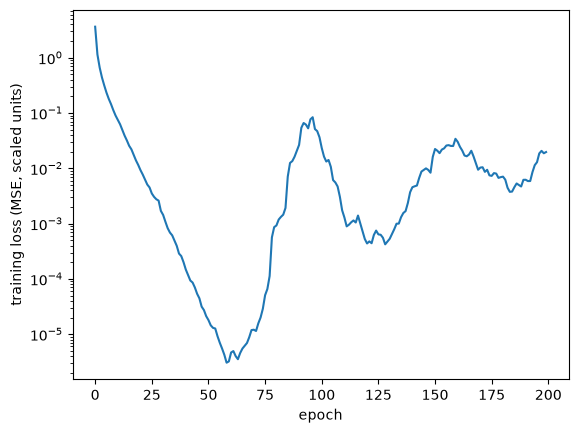

In [265]:
## Training

history = fit(model, training_set, num_epochs=200, optimizer=optimizer, p=2, verbose=False)

plt.plot(np.array(history) / len(training_set))
plt.xlabel("epoch")
plt.ylabel("training loss (MSE, scaled units)")
plt.yscale("log")
plt.show()


In [266]:
## Evaluation on fold 0

from sklearn.metrics import r2_score

model.eval()
with torch.no_grad():
    pred_tr = y_scaler.inverse_transform(model(X_tr).numpy()).ravel()
    pred_va = y_scaler.inverse_transform(model(X_va).numpy()).ravel()

print(f"train R2: {r2_score(y[train], pred_tr):.4f}")
print(f"val   R2: {r2_score(y_va, pred_va):.4f}   (SVR on the same fold ≈ 0.69)")

train R2: 0.9891
val   R2: 0.5971   (SVR on the same fold ≈ 0.69)


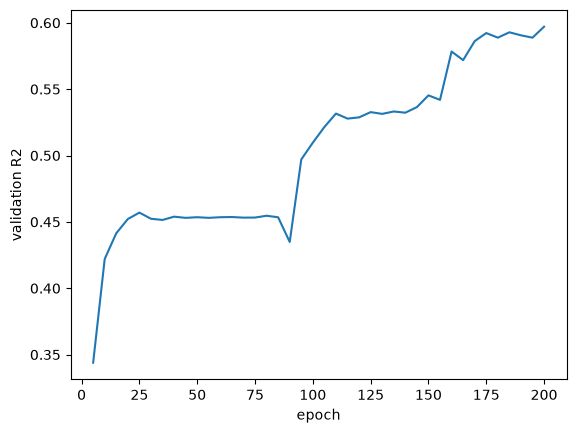

best val R2 0.5971 at epoch 200


In [267]:
## Validation R² during training

model = NeuralNet(input_dimension=216, output_dimension=1, n_hidden_layers=2, neurons=128,
                  regularization_param=0., regularization_exp=2., retrain_seed=42)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

val_curve = []
for block in range(40):                                   # 40 blocks × 5 epochs = 200 epochs
    fit(model, training_set, num_epochs=5, optimizer=optimizer, p=2, verbose=False)
    model.eval()
    with torch.no_grad():
        pred_va = y_scaler.inverse_transform(model(X_va).numpy()).ravel()
    model.train()
    val_curve.append(r2_score(y_va, pred_va))

epochs = 5 * np.arange(1, 41)
plt.plot(epochs, val_curve)
plt.xlabel("epoch")
plt.ylabel("validation R2")
plt.show()
print(f"best val R2 {max(val_curve):.4f} at epoch {epochs[np.argmax(val_curve)]}")


In [268]:
## Dropout sweep (weight_decay fixed at 1)

def train_and_score(weight_decay, dropout=0., num_epochs=200, seed=42):
    model = NeuralNet(input_dimension=216, output_dimension=1, n_hidden_layers=2, neurons=128,
                      regularization_param=0., regularization_exp=2., retrain_seed=seed, dropout=dropout)
    optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=weight_decay)
    fit(model, training_set, num_epochs=num_epochs, optimizer=optimizer, p=2, verbose=False)
    model.eval()
    with torch.no_grad():
        pred_tr = y_scaler.inverse_transform(model(X_tr).numpy()).ravel()
        pred_va = y_scaler.inverse_transform(model(X_va).numpy()).ravel()
    return r2_score(y[train], pred_tr), r2_score(y_va, pred_va)

for dr in [0, 0.1, 0.2, 0.3, 0.5]:
    r2_tr, r2_va = train_and_score(weight_decay=1, dropout=dr)
    print(f"dropout {dr:>4}: train R2 {r2_tr:.4f} | val R2 {r2_va:.4f}")

dropout    0: train R2 0.9900 | val R2 0.6807
dropout  0.1: train R2 0.9705 | val R2 0.6736
dropout  0.2: train R2 0.9576 | val R2 0.6842
dropout  0.3: train R2 0.9667 | val R2 0.6924
dropout  0.5: train R2 0.9213 | val R2 0.6909


In [269]:
## Seed variability and averaging

def train_predict(weight_decay, dropout=0., num_epochs=200, seed=42):
    model = NeuralNet(input_dimension=216, output_dimension=1, n_hidden_layers=2, neurons=128,
                      regularization_param=0., regularization_exp=2., retrain_seed=seed, dropout=dropout)
    optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=weight_decay)
    torch.manual_seed(seed)                                   # also fixes the order of the shuffled batches
    fit(model, training_set, num_epochs=num_epochs, optimizer=optimizer, p=2, verbose=False)
    model.eval()
    with torch.no_grad():
        return y_scaler.inverse_transform(model(X_va).numpy()).ravel()

preds = []
for seed in range(5):
    pred_va = train_predict(weight_decay=1, seed=seed)
    preds.append(pred_va)
    print(f"seed {seed}: val R2 {r2_score(y_va, pred_va):.4f}")

print(f"average of the 5 networks: val R2 {r2_score(y_va, np.mean(preds, axis=0)):.4f}")


seed 0: val R2 0.6780
seed 1: val R2 0.6775
seed 2: val R2 0.6987
seed 3: val R2 0.7144
seed 4: val R2 0.6897
average of the 5 networks: val R2 0.7097


In [270]:
## Network size (5-seed average)

def train_predict(weight_decay, dropout=0., num_epochs=200, seed=42, n_hidden_layers=2, neurons=128):
    model = NeuralNet(input_dimension=216, output_dimension=1, n_hidden_layers=n_hidden_layers, neurons=neurons,
                      regularization_param=0., regularization_exp=2., retrain_seed=seed, dropout=dropout)
    optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=weight_decay)
    torch.manual_seed(seed)
    fit(model, training_set, num_epochs=num_epochs, optimizer=optimizer, p=2, verbose=False)
    model.eval()
    with torch.no_grad():
        return y_scaler.inverse_transform(model(X_va).numpy()).ravel()

def seed_average_r2(n_seeds=5, **settings):
    preds = [train_predict(seed=s, **settings) for s in range(n_seeds)]
    return r2_score(y_va, np.mean(preds, axis=0))

for layers, neurons in [(2, 128), (1, 128), (1, 64), (1, 32), (1, 16)]:
    r2 = seed_average_r2(weight_decay=1, n_hidden_layers=layers, neurons=neurons)
    print(f"{layers} hidden layer(s) × {neurons:>3} neurons: val R2 (5-seed avg) {r2:.4f}")


2 hidden layer(s) × 128 neurons: val R2 (5-seed avg) 0.7097
1 hidden layer(s) × 128 neurons: val R2 (5-seed avg) 0.7090
1 hidden layer(s) ×  64 neurons: val R2 (5-seed avg) 0.7148
1 hidden layer(s) ×  32 neurons: val R2 (5-seed avg) 0.7012
1 hidden layer(s) ×  16 neurons: val R2 (5-seed avg) 0.6811


In [271]:
## Funnel vs single layer (5-seed average)

for layers, neurons in [(2, [16, 16])]:
    r2 = seed_average_r2(weight_decay=1, n_hidden_layers=layers, neurons=neurons)
    print(f"{layers} hidden layer(s) × {str(neurons):>10}: val R2 (5-seed avg) {r2:.4f}")


2 hidden layer(s) ×   [16, 16]: val R2 (5-seed avg) 0.6795


In [272]:
print(X["x115"].max())

10.862545174686922


In [273]:
## 5-fold cross-validation (shared folds)

def predict_fold(f, n_seeds=5, weight_decay=1, n_hidden_layers=1, neurons=64, num_epochs=200, loss_fn=None):
    train, val = fold != f, fold == f

    # scaling fitted on this fold's training rows only
    x_scaler = StandardScaler().fit(X[train])
    y_scaler = StandardScaler().fit(y[train].to_frame())
    X_tr = torch.tensor(x_scaler.transform(X[train]), dtype=torch.float32)
    X_va = torch.tensor(x_scaler.transform(X[val]), dtype=torch.float32)
    y_tr = torch.tensor(y_scaler.transform(y[train].to_frame()), dtype=torch.float32)
    training_set = DataLoader(torch.utils.data.TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)

    # train n_seeds networks and average their predictions
    preds = []
    for seed in range(n_seeds):
        model = NeuralNet(input_dimension=216, output_dimension=1, n_hidden_layers=n_hidden_layers, neurons=neurons,
                          regularization_param=0., regularization_exp=2., retrain_seed=seed)
        optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=weight_decay)
        torch.manual_seed(seed)
        fit(model, training_set, num_epochs=num_epochs, optimizer=optimizer, p=2, verbose=False, loss_fn=loss_fn)
        model.eval()
        with torch.no_grad():
            preds.append(y_scaler.inverse_transform(model(X_va).numpy()).ravel())
    return np.mean(preds, axis=0)

svr_fold = [0.7426, 0.7123, 0.6751, 0.7003, 0.7067]   # SVR on log_knn, per fold

oof = pd.Series(np.nan, index=X.index, name="mlp")
for f in range(5):
    oof[fold == f] = predict_fold(f)
    print(f"fold {f}: MLP R2 {r2_score(y[fold == f], oof[fold == f]):.4f} | SVR {svr_fold[f]:.4f}")

print(f"out-of-fold R2: MLP {r2_score(y, oof):.4f} | SVR 0.6935")


fold 0: MLP R2 0.7148 | SVR 0.7426
fold 1: MLP R2 0.6830 | SVR 0.7123
fold 2: MLP R2 0.6334 | SVR 0.6751
fold 3: MLP R2 0.6895 | SVR 0.7003
fold 4: MLP R2 0.7029 | SVR 0.7067
out-of-fold R2: MLP 0.6861 | SVR 0.6935


In [275]:
## Out-of-fold predictions: save and compare with the other models

oof.to_csv("Stacking/oof_mlp.csv")

files = {"svr": "oof_svr.csv", "xgb": "oof_xgb.csv", "gp": "oof_gp.csv", "mlp": "oof_mlp.csv"}
all_oof = pd.concat({name: pd.read_csv(f"Stacking/{file}", index_col="id").iloc[:, 0]
                     for name, file in files.items()}, axis=1).loc[X.index]

print("correlation of the errors:")
print(all_oof.sub(y, axis=0).corr().round(3))
print()
print(f"average without MLP : R2 {r2_score(y, all_oof.drop(columns='mlp').mean(axis=1)):.4f}")
print(f"average with MLP    : R2 {r2_score(y, all_oof.mean(axis=1)):.4f}")


correlation of the errors:
       svr    xgb     gp    mlp
svr  1.000  0.841  0.818  0.874
xgb  0.841  1.000  0.722  0.814
gp   0.818  0.722  1.000  0.769
mlp  0.874  0.814  0.769  1.000

average without MLP : R2 0.7349
average with MLP    : R2 0.7359


In [276]:
## Final model: train on all 1152 rows, predict the 776 test rows

import os

X_test = pd.read_csv("X_test_log_knn.csv", index_col="id")

x_scaler = StandardScaler().fit(X)
y_scaler = StandardScaler().fit(y.to_frame())
X_all = torch.tensor(x_scaler.transform(X), dtype=torch.float32)
X_te = torch.tensor(x_scaler.transform(X_test), dtype=torch.float32)
y_all = torch.tensor(y_scaler.transform(y.to_frame()), dtype=torch.float32)
training_set = DataLoader(torch.utils.data.TensorDataset(X_all, y_all), batch_size=64, shuffle=True)

preds = []
for seed in range(5):
    model = NeuralNet(input_dimension=216, output_dimension=1, n_hidden_layers=1, neurons=64,
                      regularization_param=0., regularization_exp=2., retrain_seed=seed)
    optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1)
    torch.manual_seed(seed)
    fit(model, training_set, num_epochs=200, optimizer=optimizer, p=2, verbose=False)
    model.eval()
    with torch.no_grad():
        preds.append(y_scaler.inverse_transform(model(X_te).numpy()).ravel())

os.makedirs("MLP", exist_ok=True)
pd.Series(np.mean(preds, axis=0), index=X_test.index, name="y").to_csv("MLP/submission_mlp.csv")
print(pd.read_csv("MLP/submission_mlp.csv").describe().round(1))


          id      y
count  776.0  776.0
mean   387.5   69.8
std    224.2    8.3
min      0.0   48.1
25%    193.8   64.2
50%    387.5   70.4
75%    581.2   75.9
max    775.0   87.6
